In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Read image
image = cv2.imread("sink.jpg", 0)

In [3]:
# Convert to binary
_, binary = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY)

In [4]:
# Create kernel
kernel = np.ones((3, 3), np.uint8)

In [10]:
def erosion(image,kernal):
    h,w=image.shape
    result =np.zeros((h,w))
    for i in range(1,h-1):
        for j in range(1,w-1):
            region = image[i-1:i+2, j-1:j+2]
            if(np.all(region[kernal==1]==255)):
                result[i][j]=255
            else:
                result[i][j]=0
    return result

In [11]:
# Erosion
# eroded = cv2.erode(binary, kernel, iterations=1)
eroded_image = erosion(binary, kernel)

In [12]:
# Boundary extraction
boundary = binary - eroded

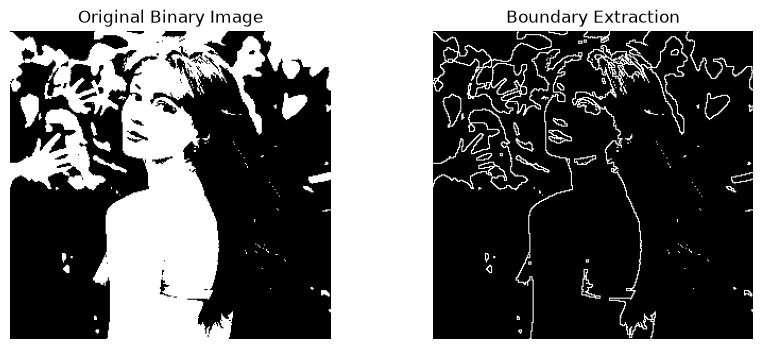

In [13]:

# Display
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(boundary, cmap="gray")
plt.title("Boundary Extraction")
plt.axis("off")

plt.show()